# 02 · Eksik Veri Analizi: MCAR mı, MAR mı, MNAR mı?

**Projenin ana sorusu:** Hastaların cevaplamadığı sorular rastgele mi; eksikliğin kendisi riskle ilişkili mi?

### Üç eksiklik mekanizması (Rubin, 1976)

| Mekanizma | Anlamı | Bu veri setinde örnek |
|---|---|---|
| **MCAR** (Missing Completely At Random) | Eksiklik hiçbir şeye bağlı değil; tamamen şans | Anket kâğıdı rastgele yırtılmış |
| **MAR** (Missing At Random) | Eksiklik **gözlenen** başka bir değişkene bağlı | Gençler mahrem soruları daha sık boş bırakıyor (yaş gözleniyor) |
| **MNAR** (Missing Not At Random) | Eksiklik **eksik olan değerin kendisine** ya da gözlenmeyen bir şeye bağlı | CYBH'si olanlar tam da bu yüzden CYBH sorusunu cevaplamıyor |

**Neden önemli?**
- MCAR ise eksik satırları silmek sadece veri kaybıdır, sonucu yanlı (biased) yapmaz.
- MAR ise silmek yanlılık yaratır; ama gözlenen değişkenlerle doldurmak (imputasyon) bunu düzeltebilir.
- MNAR ise hiçbir imputasyon tam düzeltemez; eksikliğin kendisini modele bilgi olarak vermek (gösterge) ve duyarlılık analizi gerekir.

**Bu notebook'un planı:**
1. Eksiklik göstergelerini oluştur, hangi soruların birlikte boş bırakıldığına bak
2. **Little MCAR testi**: genel bir MCAR testi
3. **MAR kanıtı**: eksiklik, gözlenen değişkenlerle (yaş vb.) ilişkili mi?
4. **Eksiklik ↔ biyopsi**: eksiklik hedefle ilişkili mi? (Fisher testi, yaşa göre düzeltilmiş Mantel-Haenszel)
5. Eksik satırları silseydik ne olurdu? (complete-case analizi)
6. Sonuç ve 03 için çıkarımlar

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests

from src.utils import load_raw, clean, missing_indicators, little_mcar_test, wilson_ci, FEATURES, MISSING_GROUPS

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", font_scale=0.9)
FIG = Path("../results/figures")
TAB = Path("../results/tables")

## 0. Veriyi yükle ve 01'deki hataları düzelt

`clean()` fonksiyonu (`src/utils.py`) iki düzeltme yapıyor, **doldurma yapmıyor**:
- İlk ilişki yaşı > şimdiki yaş olan 2 değer → `NaN`
- CYBH soruları cevapsızken `0` yazılmış `STDs: Number of diagnosis` → `NaN` (gizli eksik)

In [2]:
raw = load_raw()
df = clean(raw)

print("İlk ilişki yaşı eksik:          ", raw["First sexual intercourse"].isna().sum(), "→", df["First sexual intercourse"].isna().sum())
print("STDs: Number of diagnosis eksik: ", raw["STDs: Number of diagnosis"].isna().sum(), "→", df["STDs: Number of diagnosis"].isna().sum())

İlk ilişki yaşı eksik:           7 → 9
STDs: Number of diagnosis eksik:  0 → 105


## 1. Eksiklik göstergeleri

Her soru grubu için "bu hasta bu grubu cevaplamadı mı?" (1 = eksik) göstergesi oluşturuyoruz. Bir grubun içindeki sütunlar hep birlikte eksik olduğu için (01'de gördük) her gruptan bir temsilci sütun yeterli.

Ek olarak **"Hassas blok"** göstergesi: hormonal kontraseptif, RİA veya CYBH sorularından **en az birini** cevaplamamış hastalar.

In [3]:
I = missing_indicators(df)
I["Hassas blok"] = I[["HK", "RİA", "CYBH"]].max(axis=1)

summary = pd.DataFrame({"eksik_hasta": I.sum(), "oran_%": (I.mean() * 100).round(1)})
summary

,eksik_hasta,oran_%
Partner,26,3.0
İlk ilişki,9,1.0
Gebelik,56,6.5
Sigara,13,1.5
HK,108,12.6
RİA,117,13.6
CYBH,105,12.2
Hassas blok,124,14.5


### 1a. Hangi gruplar birlikte boş bırakılıyor?

İki gösterge arasındaki korelasyon (ikili değişkenlerde buna **phi katsayısı** denir). 1'e yakın = hep birlikte eksik.

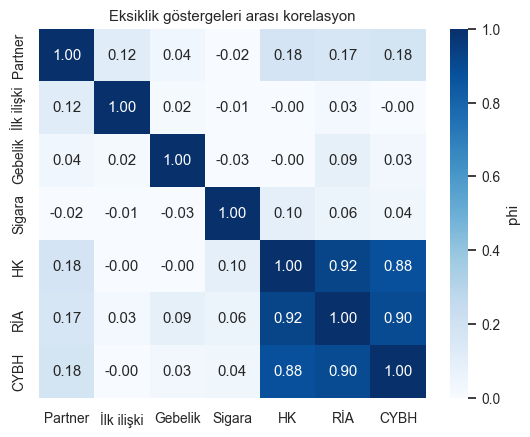

In [4]:
phi = I.drop(columns="Hassas blok").corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(phi, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "phi"})
ax.set_title("Eksiklik göstergeleri arası korelasyon")
plt.tight_layout()
plt.savefig(FIG / "02_eksiklik_birlikteligi.png", dpi=150)
plt.show()

**Yorum:** HK, RİA ve CYBH göstergeleri arasında phi ≈ 0.9: bu üç grup neredeyse her zaman **birlikte** boş. Diğer gruplar (gebelik, sigara, partner, ilk ilişki) birbirinden bağımsız eksik.

Yani iki ayrı eksiklik süreci var:
1. **Hassas blok:** mahrem soruların toplu olarak atlanması (124 hasta)
2. **Tekil eksikler:** tek tük, dağınık cevapsız sorular

## 2. Little MCAR testi

Little (1988) testi şu soruyu sorar: *Farklı eksiklik desenine sahip hasta gruplarının gözlenen değişken ortalamaları birbirinden farklı mı?* MCAR doğruysa tüm desenlerde ortalamalar aynı olmalı.

- **H₀:** Veri MCAR.
- **p < 0.05** → MCAR reddedilir.
- Uygulama `src/utils.py` içinde (EM algoritmasıyla ortalama/kovaryans tahmini + ki-kare istatistiği). Simülasyonla doğrulandı: MCAR veride %7.5 yanlış alarm (beklenen ≈%5), MAR veride %100 tespit.

In [5]:
num = ["Age", "Number of sexual partners", "First sexual intercourse", "Num of pregnancies",
       "Smokes (years)", "Smokes (packs/year)", "Hormonal Contraceptives (years)", "IUD (years)", "STDs (number)"]

tests = {
    "Sayısal öznitelikler (9)":                num,
    "+ Biyopsi":                               num + ["Biopsy"],
    "+ Biyopsi + önceki tanılar (Dx)":         num + ["Biopsy", "Dx:Cancer", "Dx:CIN", "Dx:HPV"],
}
rows = []
for name, cols in tests.items():
    chi2, dof, p, n_pat = little_mcar_test(df[cols])
    rows.append({"değişken seti": name, "χ²": round(chi2, 1), "sd": dof, "p": round(p, 4), "desen sayısı": n_pat})
little = pd.DataFrame(rows)
little

,değişken seti,χ²,sd,p,desen sayısı
0,Sayısal öznitelikler (9),148.1,148,0.4824,24
1,+ Biyopsi,172.7,171,0.4483,24
2,+ Biyopsi + önceki tanılar (Dx),290.1,240,0.0148,24


**Yorum: dikkatli olunmalı.**

Sadece sayısal özniteliklerle Little testi MCAR'ı **reddetmiyor** (p ≈ 0.48). Bu "veri MCAR'dır" demek **değil**:
- **Düşük güç:** Test tüm desenleri tek bir istatistikte birleştiriyor (148 serbestlik derecesi). 24 desenin çoğunda 1–10 hasta var; küçük ama gerçek farklar bu kadar çok serbestlik derecesi arasında kayboluyor.
- **Normallik varsayımı:** Test çok değişkenli normal dağılım varsayıyor. Bizim değişkenlerimiz çok çarpık ve çoğunlukla 0 (sigara yılı, RİA yılı).
- Önceki tanılar (Dx) eklendiğinde test **MCAR'ı reddediyor** (p ≈ 0.015).

Literatürde de bu yüzden Little testinin tek başına yeterli olmadığı, **hedefe yönelik testlerle** desteklenmesi gerektiği vurgulanır. Sonraki iki bölümde bunu yapıyoruz.

## 3. MAR kanıtı: eksiklik gözlenen değişkenlerle ilişkili mi?

Her eksiklik grubu için: o grubu cevaplamayan hastalarla cevaplayanların **diğer** değişkenleri farklı mı? Dağılımlar çarpık olduğu için ortalama yerine **medyan** ve **Mann-Whitney U testi** kullanıyoruz.

In [6]:
compare_vars = ["Age", "First sexual intercourse", "Number of sexual partners", "Num of pregnancies"]
rows = []
for g in ["Hassas blok", "Gebelik", "Partner", "Sigara"]:
    m = I[g] == 1
    for v in compare_vars:
        if v == MISSING_GROUPS.get(g):
            continue  # bir değişkeni kendi eksikliğiyle karşılaştıramayız
        x, y = df.loc[m, v].dropna(), df.loc[~m, v].dropna()
        rows.append({"eksik grup": g, "değişken": v, "n_eksik": len(x),
                     "medyan (eksik)": x.median(), "medyan (dolu)": y.median(),
                     "p": stats.mannwhitneyu(x, y).pvalue})
mar = pd.DataFrame(rows)
mar["p_holm"] = multipletests(mar["p"], method="holm")[1]
mar["anlamlı"] = np.where(mar["p_holm"] < 0.05, "✔", "")
mar.round(4)

,eksik grup,değişken,n_eksik,medyan (eksik),medyan (dolu),p,p_holm,anlamlı
0,Hassas blok,Age,124,23.0,26.0,0.0006,0.0077,✔
1,Hassas blok,First sexual intercourse,122,16.0,17.0,0.0065,0.0846,
2,Hassas blok,Number of sexual partners,112,2.0,2.0,0.9843,1.0000,
3,Hassas blok,Num of pregnancies,109,2.0,2.0,0.0226,0.2712,
4,Gebelik,Age,56,26.0,25.0,0.4992,1.0000,
5,Gebelik,First sexual intercourse,55,17.0,17.0,0.3549,1.0000,
6,Gebelik,Number of sexual partners,53,2.0,2.0,0.1845,1.0000,
7,Partner,Age,26,25.0,25.0,0.7904,1.0000,
8,Partner,First sexual intercourse,24,16.5,17.0,0.5637,1.0000,
9,Partner,Num of pregnancies,23,2.0,2.0,0.3706,1.0000,


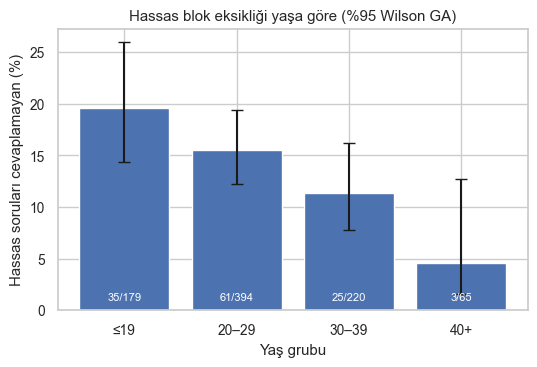

Ki-kare (yaş grubu × hassas blok eksikliği) p = 0.01234


In [7]:
age_grp = pd.cut(df["Age"], [0, 19, 29, 39, 100], labels=["≤19", "20–29", "30–39", "40+"])
rate = I.groupby(age_grp, observed=True)["Hassas blok"].agg(["sum", "count"])
ci = np.array([wilson_ci(k, n) for k, n in zip(rate["sum"], rate["count"])])
p_hat = rate["sum"] / rate["count"]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.bar(rate.index.astype(str), p_hat * 100, yerr=[(p_hat - ci[:, 0]) * 100, (ci[:, 1] - p_hat) * 100],
       capsize=4, color=sns.color_palette()[0])
for i, (k, n) in enumerate(zip(rate["sum"], rate["count"])):
    ax.text(i, 1, f"{k}/{n}", ha="center", color="white", fontsize=8)
ax.set_xlabel("Yaş grubu")
ax.set_ylabel("Hassas soruları cevaplamayan (%)")
ax.set_title("Hassas blok eksikliği yaşa göre (%95 Wilson GA)")
plt.tight_layout()
plt.savefig(FIG / "02_eksiklik_yas.png", dpi=150)
plt.show()

print("Ki-kare (yaş grubu × hassas blok eksikliği) p =",
      round(stats.chi2_contingency(pd.crosstab(age_grp, I["Hassas blok"]))[1], 5))

**Yorum:** Hassas soruları cevaplamayan hastalar **daha genç** (medyan 23'e karşı 26 yaş; Holm düzeltmesi sonrası da anlamlı). Grafikte cevapsızlık oranı yaş arttıkça düzenli olarak azalıyor (ki-kare p ≈ 0.01). İlk ilişki yaşı ve gebelik sayısında da benzer farklar var, ama Holm düzeltmesinden sonra anlamlı değiller.

→ Eksiklik gözlenen bir değişkene (yaşa) bağlı. Bu **MCAR'a karşı açık bir kanıt** ve **MAR ile uyumlu**.

Gebelik, partner ve sigara eksiklikleri ise yaşla ilişkili görünmüyor. Bunlar MCAR'a daha yakın, dağınık eksikler.

## 4. Eksiklik biyopsi sonucuyla ilişkili mi?

Projenin asıl sorusu. Her gösterge için 2×2 tablo kuruyoruz:

|  | Biyopsi + | Biyopsi − |
|---|---|---|
| **Eksik** | a | b |
| **Dolu** | c | d |

- **Fisher kesin testi:** Hücrelerde 0–7 gibi küçük sayılar olduğu için ki-kare yerine kullanılır.
- **Odds oranı (OR):** OR < 1 → eksik olanlarda biyopsi pozitifliği daha az.
- **Holm düzeltmesi:** 8 test yaptığımız için şans eseri anlamlı çıkma riskini kontrol eder.
- **Yaşa göre düzeltilmiş (Mantel-Haenszel) test:** Bölüm 3'te eksikliğin yaşla ilişkili olduğunu gördük. Gençlerde biyopsi pozitifliği de daha düşükse, eksiklik-biyopsi ilişkisi sadece **yaştan kaynaklanıyor** olabilir (karıştırıcı etken, *confounding*). MH testi aynı yaş grubundaki hastaları kendi içinde karşılaştırır.

In [8]:
print("Yaş grubuna göre biyopsi pozitifliği (%):")
print((df.groupby(age_grp, observed=True)["Biopsy"].mean() * 100).round(1).to_string())

Yaş grubuna göre biyopsi pozitifliği (%):
Age
≤19      3.4
20–29    7.1
30–39    6.8
40+      9.2


In [9]:
y = df["Biopsy"]
rows = []
for g in I.columns:
    m = I[g] == 1
    a, b = int(y[m].sum()), int((1 - y[m]).sum())
    c, d = int(y[~m].sum()), int((1 - y[~m]).sum())
    OR, p = stats.fisher_exact([[a, b], [c, d]])

    strata = []
    for k in age_grp.cat.categories:
        s = age_grp == k
        t = np.array([[y[m & s].sum(), (1 - y[m & s]).sum()], [y[~m & s].sum(), (1 - y[~m & s]).sum()]])
        if t.sum(axis=1).min() > 0:  # o yaş grubunda hem eksik hem dolu hasta olmalı
            strata.append(t)
    mh = StratifiedTable(strata)

    lo_e, hi_e = wilson_ci(a, a + b)
    rows.append({"gösterge": g, "n_eksik": a + b,
                 "biyopsi+ eksik": f"{a}/{a+b} (%{a/(a+b)*100:.1f})",
                 "biyopsi+ dolu": f"{c}/{c+d} (%{c/(c+d)*100:.1f})",
                 "GA eksik (%)": f"{lo_e*100:.1f}–{hi_e*100:.1f}",
                 "OR": round(OR, 2), "p_Fisher": p,
                 "OR_MH (yaş)": round(mh.oddsratio_pooled, 2), "p_MH (yaş)": mh.test_null_odds(correction=True).pvalue})

assoc = pd.DataFrame(rows)
assoc["p_Holm"] = multipletests(assoc["p_Fisher"], method="holm")[1]
assoc.to_csv(TAB / "02_eksiklik_biyopsi_testleri.csv", index=False, encoding="utf-8-sig")
assoc.round(4)

,gösterge,n_eksik,biyopsi+ eksik,biyopsi+ dolu,GA eksik (%),OR,p_Fisher,OR_MH (yaş),p_MH (yaş),p_Holm
0,Partner,26,1/26 (%3.8),54/832 (%6.5),0.7–18.9,0.58,1.0000,0.59,0.9105,1.0000
1,İlk ilişki,9,0/9 (%0.0),55/849 (%6.5),0.0–29.9,0.00,1.0000,0.00,0.9052,1.0000
2,Gebelik,56,7/56 (%12.5),48/802 (%6.0),6.2–23.6,2.24,0.0809,2.26,0.0894,0.4142
3,Sigara,13,1/13 (%7.7),54/845 (%6.4),1.4–33.3,1.22,0.5800,1.35,0.7549,1.0000
4,HK,108,0/108 (%0.0),55/750 (%7.3),0.0–3.4,0.00,0.0011,0.00,0.0101,0.0084
5,RİA,117,3/117 (%2.6),52/741 (%7.0),0.9–7.3,0.35,0.0690,0.37,0.1356,0.4142
6,CYBH,105,2/105 (%1.9),53/753 (%7.0),0.5–6.7,0.26,0.0524,0.27,0.0979,0.3671
7,Hassas blok,124,4/124 (%3.2),51/734 (%6.9),1.3–8.0,0.45,0.1627,0.48,0.2218,0.6507


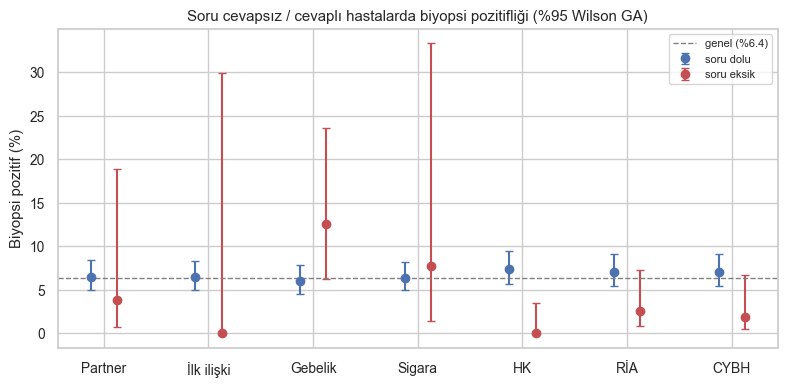

In [10]:
plot = []
for g in ["Partner", "İlk ilişki", "Gebelik", "Sigara", "HK", "RİA", "CYBH"]:
    m = I[g] == 1
    for lab, mask in [("eksik", m), ("dolu", ~m)]:
        k, n = int(y[mask].sum()), int(mask.sum())
        lo, hi = wilson_ci(k, n)
        plot.append({"grup": g, "durum": lab, "oran": k / n * 100, "lo": lo * 100, "hi": hi * 100, "n": n})
plot = pd.DataFrame(plot)

fig, ax = plt.subplots(figsize=(8, 4))
groups = plot["grup"].unique()
xs = np.arange(len(groups))
for j, (lab, col) in enumerate([("dolu", sns.color_palette()[0]), ("eksik", sns.color_palette()[3])]):
    p = plot[plot["durum"] == lab].set_index("grup").loc[groups]
    ax.errorbar(xs + (j - 0.5) * 0.25, p["oran"], yerr=[p["oran"] - p["lo"], p["hi"] - p["oran"]],
                fmt="o", capsize=3, color=col, label=f"soru {lab}")
ax.axhline(y.mean() * 100, ls="--", color="grey", lw=1, label=f"genel (%{y.mean()*100:.1f})")
ax.set_xticks(xs)
ax.set_xticklabels(groups)
ax.set_ylabel("Biyopsi pozitif (%)")
ax.set_title("Soru cevapsız / cevaplı hastalarda biyopsi pozitifliği (%95 Wilson GA)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "02_eksiklik_biyopsi.png", dpi=150)
plt.show()

**Yorum:**

- **Hormonal kontraseptif (HK) sorusu:** Cevaplamayan 108 hastanın **hiçbirinde** biyopsi pozitif değil (cevaplayanlarda %7.3). Fisher p ≈ 0.001, 8 test için Holm düzeltmesinden sonra da **anlamlı** (p ≈ 0.009). Yaşa göre düzeltildiğinde de anlamlılık sürüyor (MH p ≈ 0.01). Yani bu ilişki sadece "gençler hem cevapsız bırakıyor hem daha az pozitif" etkisiyle açıklanamıyor.
- **RİA ve CYBH:** Aynı yönde (cevapsızlarda pozitiflik %2–3) ama anlamlı değil. Pozitif sayısı çok az olduğu için testin gücü düşük. Güven aralıkları geniş.
- **Gebelik sayısı:** Ters yönde: cevapsızlarda pozitiflik daha **yüksek** (%12.5, OR ≈ 2.2). Ama ne ham (p ≈ 0.08) ne yaşa göre düzeltilmiş test (p ≈ 0.09) anlamlı. → En fazla "olası sinyal" olarak raporlanabilir.
- **Partner, ilk ilişki, sigara:** Eksik hasta sayısı çok az (9–26). Hiçbir sonuç çıkarılamaz.

**Önemli uyarı:** 108 hastada 0 pozitif çarpıcı ama tam olarak 0 olması, küçük örneklemde şansa da bağlı olabilir. Oranın %95 güven aralığı %0–3.4; yani gerçek oran %3 civarında da olabilir. 04'te bootstrap ile modelin bu bilgiye ne kadar yaslandığını ölçeceğiz.

## 5. Eksik satırları silseydik ne olurdu? (complete-case analizi)

En basit yaklaşım, eksiği olan her satırı silmek (`df.dropna()`). Modelde kullanacağımız 15 öznitelik için bunun etkisi:

In [11]:
cc = df.dropna(subset=FEATURES)
print(f"Kalan hasta:          {len(cc)} / {len(df)}  (%{len(cc)/len(df)*100:.0f})")
print(f"Kalan biyopsi+:       {int(cc['Biopsy'].sum())} / {int(df['Biopsy'].sum())}")
print(f"Biyopsi+ oranı:       %{df['Biopsy'].mean()*100:.1f}  →  %{cc['Biopsy'].mean()*100:.1f}")
print(f"Medyan yaş:           {df['Age'].median():.0f}  →  {cc['Age'].median():.0f}")
print(f"≤19 yaş hasta oranı:  %{(df['Age'] <= 19).mean()*100:.1f}  →  %{(cc['Age'] <= 19).mean()*100:.1f}")

Kalan hasta:          668 / 858  (%78)
Kalan biyopsi+:       45 / 55
Biyopsi+ oranı:       %6.4  →  %6.7
Medyan yaş:           25  →  26
≤19 yaş hasta oranı:  %20.9  →  %19.3


**Yorum:** Pozitiflik oranı ve yaştaki kayma **küçük** (%6.4 → %6.7; medyan yaş 25 → 26). Yani bu veride silmenin genel dağılımı bozan büyük bir etkisi yok. Yine de silmemek için üç güçlü neden var:
- **Nadir sınıf kaybı:** Zaten az olan 55 pozitifin 10'u (%18) gidiyor. Her pozitif örnek değerli.
- **Bilgi kaybı:** Bölüm 4'te eksikliğin kendisinin hedefle ilişkili olduğunu gördük. Satırları silersek model bu bilgiyi hiç göremez.
- **Uygulamada işe yaramaz:** Gerçek klinikte de bazı hastalar bu soruları cevaplamayacak. Sadece eksiksiz hastalarla eğitilmiş bir model, ≈%22'lik bu gruba tahmin üretemez.

→ **Satır silmeyeceğiz**, imputasyon yapacağız.

## 6. Sonuç: hangi mekanizma?

| Kanıt | Sonuç |
|---|---|
| Hassas sorular (HK, RİA, CYBH) neredeyse hep birlikte boş (phi ≈ 0.9) | Soru soru değil, **blok halinde** cevapsızlık |
| Little testi (sayısal) p ≈ 0.48, Dx eklenince p ≈ 0.015 | Genel test zayıf; tek başına karar verdirmiyor |
| Cevapsızlar daha genç (Mann-Whitney, Holm sonrası anlamlı) | **MCAR değil**: eksiklik gözlenen yaşa bağlı → en az **MAR** |
| HK cevapsızlarında 0/108 biyopsi+, yaşa göre düzeltildikten sonra da anlamlı | Eksiklik, yaşın açıklayamadığı biçimde **hedefle ilişkili** |

**MAR mı MNAR mı?**
Bu ayrımı veriden **istatistiksel olarak yapmak mümkün değil**: MNAR'ı test etmek için eksik değerlerin kendisini bilmemiz gerekir. Ama alan bilgisi yorum yapmaya izin veriyor:
- UCI veri seti açıklamasına göre bazı hastalar **mahremiyet kaygısıyla** bazı soruları cevaplamamayı seçmiş. Yani eksiklik bir **tercih**.
- Mahrem soruyu cevaplamama kararı, sorunun cevabıyla (örneğin CYBH öyküsü) ilişkili olabilir. Bu MNAR olurdu.
- Öte yandan cevapsızlar daha genç ve biyopsi pozitifliği daha düşük. Bu da örneğin daha erken bir tarama aşamasında olmalarına, ya da farklı bir hasta profiline (gözlenmeyen değişkenler) işaret ediyor olabilir.

**En dürüst ifade:** Veri **MCAR değildir**; eksiklik en azından yaşa bağlıdır (MAR) ve yaşla açıklanamayan biçimde hedefle de ilişkilidir. Bu yüzden **MNAR olasılığı dışlanamaz**.

### 03 için çıkarımlar
1. **Satır silme yok.** Pozitiflerin %18'ini ve eksikliğin taşıdığı bilgiyi kaybettirir.
2. **İmputasyon + eksiklik göstergesi** (`add_indicator=True`): Eksikliğin taşıdığı bilgi modele verilmeli. HK göstergesinin modelde önemli çıkması bekleniyor.
3. **Karşılaştırma:** Göstergesiz ve göstergeli imputasyon aynı çapraz doğrulama düzeninde karşılaştırılacak.
4. **Hassas blok tek bir gösterge olabilir:** HK, RİA ve CYBH göstergeleri neredeyse aynı (phi ≈ 0.9). Üçünü ayrı vermek yerine tek bir "hassas blok eksik" göstergesi daha kararlı olabilir.
5. **Etik not (05):** Model "soruyu cevaplamadı → düşük risk" öğrenirse bu klinik olarak tehlikeli bir kısayol olabilir. Bu genellenebilir bir biyolojik ilişki değil, bu veri setinin toplanma biçimine özgü olabilir.